In [15]:
import tables as tb
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import pyvista as pv
import pathlib
import pandas as pd
import math


In [16]:
lt_directory = '../out/xe_lt'
lt2_directory = '../out/xe_lt_s2'

In [17]:
sorted(pathlib.Path(lt_directory).glob('*.h5'))

[PosixPath('../out/xe_lt/xe_lt_0000.h5'),
 PosixPath('../out/xe_lt/xe_lt_0001.h5'),
 PosixPath('../out/xe_lt/xe_lt_0002.h5'),
 PosixPath('../out/xe_lt/xe_lt_0003.h5'),
 PosixPath('../out/xe_lt/xe_lt_0004.h5'),
 PosixPath('../out/xe_lt/xe_lt_0005.h5'),
 PosixPath('../out/xe_lt/xe_lt_0006.h5'),
 PosixPath('../out/xe_lt/xe_lt_0007.h5'),
 PosixPath('../out/xe_lt/xe_lt_0008.h5'),
 PosixPath('../out/xe_lt/xe_lt_0009.h5'),
 PosixPath('../out/xe_lt/xe_lt_0010.h5')]

In [18]:
help(tb.group)

Help on module tables.group in tables:

NAME
    tables.group - Here is defined the Group class.

CLASSES
    tables.hdf5extension.Group(tables.hdf5extension.Node)
        Group(tables.hdf5extension.Group, tables.node.Node)
            MarkG(tables.node.NotLoggedMixin, Group)
            RootGroup
            TransactionG(tables.node.NotLoggedMixin, Group)
            TransactionGroupG(tables.node.NotLoggedMixin, Group)
    tables.node.Node(builtins.object)
        Group(tables.hdf5extension.Group, tables.node.Node)
            MarkG(tables.node.NotLoggedMixin, Group)
            RootGroup
            TransactionG(tables.node.NotLoggedMixin, Group)
            TransactionGroupG(tables.node.NotLoggedMixin, Group)
    tables.node.NotLoggedMixin(builtins.object)
        MarkG(tables.node.NotLoggedMixin, Group)
        TransactionG(tables.node.NotLoggedMixin, Group)
        TransactionGroupG(tables.node.NotLoggedMixin, Group)

    class Group(tables.hdf5extension.Group, tables.node.Node)
 

In [19]:
for path in sorted(pathlib.Path(lt_directory).glob('*.h5')):
    with tb.open_file(path, 'r') as file:
        print(file.root.MC.__str__)
        # print(file.root.MC.__dict__)
        # print(file.root.MC.__getitem__('sources').read())
        


<bound method Group.__str__ of /MC (Group) ''
  children := ['config' (Table), 'sensor_hits' (Table), 'sources' (Table)]>
<bound method Group.__str__ of /MC (Group) ''
  children := ['config' (Table), 'sensor_hits' (Table), 'sources' (Table)]>
<bound method Group.__str__ of /MC (Group) ''
  children := ['config' (Table), 'sensor_hits' (Table), 'sources' (Table)]>
<bound method Group.__str__ of /MC (Group) ''
  children := ['config' (Table), 'sensor_hits' (Table), 'sources' (Table)]>
<bound method Group.__str__ of /MC (Group) ''
  children := ['config' (Table), 'sensor_hits' (Table), 'sources' (Table)]>
<bound method Group.__str__ of /MC (Group) ''
  children := ['config' (Table), 'sensor_hits' (Table), 'sources' (Table)]>
<bound method Group.__str__ of /MC (Group) ''
  children := ['config' (Table), 'sensor_hits' (Table), 'sources' (Table)]>
<bound method Group.__str__ of /MC (Group) ''
  children := ['config' (Table), 'sensor_hits' (Table), 'sources' (Table)]>
<bound method Group.__st

help(tb.Table)

In [20]:
for path in sorted(pathlib.Path(lt_directory).glob('*.h5')):
    with tb.open_file(path, 'r') as file:
        # print(file.root.MC.sources.read())
        # print(file.root.MC.sources.dtype)
        print(file.root.MC.sources.colnames)
        print(file.root.MC.sensor_hits.colnames)



['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']


In [21]:
def data_reading(path:str, table:str):
    """Function that reads  a table contained in an h5 file and returns 
        the information contained in it in a pandas dataframe

    Args:
        path (str): path to the h5 file
        table (str): table in the file that is read

    Returns:
        pd.Dataframe: Dataframe whose headers are the columns of the table
    """
    with tb.open_file(path, 'r') as file:
        data = file.root.MC.__getitem__(table).read()
        # print(data.shape)
        column_names = file.root.MC.__getitem__(table).colnames

    dataframe = pd.DataFrame(data=data, columns=column_names)
    return dataframe

In [22]:
for path in sorted(pathlib.Path(lt_directory).glob('*.h5')):
    with tb.open_file(path, 'r') as file:
        print(data_reading(path, 'sensor_hits'))

         event  sensor_id      time
0            0         33  0.175432
1            0         78  0.362084
2            0         43  0.165855
3            0         19  0.679695
4            0         61  0.294681
...        ...        ...       ...
1107767   9999          9  0.424313
1107768   9999         78  0.178584
1107769   9999         68  0.148265
1107770   9999         35  0.557173
1107771   9999         49  0.170646

[1107772 rows x 3 columns]
         event  sensor_id      time
0        10000         84  0.207160
1        10000         77  0.438720
2        10000         82  0.270538
3        10000         84  0.166668
4        10000         85  0.191724
...        ...        ...       ...
1105136  19999         76  0.474444
1105137  19999         60  0.192515
1105138  19999         82  0.202408
1105139  19999         64  0.269394
1105140  19999         22  0.398942

[1105141 rows x 3 columns]
         event  sensor_id      time
0        20000         14  0.166203
1       

In [23]:
def data_reading_wo_pd(path:str, table:str) -> tuple[np.ndarray, list[str]]:
    """Function that reads a table from an h5 file, returning a ndarray with the data and
        a list with the headers' names

    Args:
        path (str): Pathto the h5 file 
        table (str): table in the file that is read

    Returns:
        tuple[np.ndarray, list[str]]: 
    """

    with tb.open_file(path, 'r') as file:
            data = file.root.MC.__getitem__(table).read()
        #     print(data)
            column_names = file.root.MC.__getitem__(table).colnames
    return data, column_names


def full_data_reading_wo_pd(dir_path:str, table:str) -> np.ndarray:
    """Function that readsa table from all h5 files from a directory and returns an array with all the data

    Args:
        dir_path (str): path of the directory whichis to be read
        table (str): table to be read from all h5 files

    Returns:
        np.ndarray: array with all the table data from the directory
    """
    buffer = []
    for path in pathlib.Path(dir_path).glob('*.h5'):
          single_path_data, _ = data_reading_wo_pd(path, table)
          buffer.append(single_path_data)

    stacked_data = np.concatenate(buffer)
    return stacked_data

In [24]:
config, _ = data_reading_wo_pd('../out/xe_lt_s2/xe_lt_s2_0000.h5', 'config')

# thin_wire_pitch = float(config[config['name'] == b'thin_wire_pitch']['value'][0])

In [25]:
def sipm_position(copy_no:int, config:np.ndarray) -> tuple[float, float, float]:#the z position is computed for the cylinder
    """Return the (x, y, z) center position of a SiPM in mm,
        given its Geant4 copy number.

    Args:
        copy_no (int): copy number of the requested SIPM
        config (np.ndarray): array with the geometry configuration parameters

    Returns:
        tuple[float, float, float]: (x, y, z) position of the requested SIPM
    """

    n_sipm_side = float(config[config['name'] == b'n_sipm_side']['value'][0])
    sipm_size = float(config[config['name'] == b'sipm_size']['value'][0])
    sipm_gap = float(config[config['name'] == b'sipm_gap']['value'][0])
    frame_thick_mesh = float(config[config['name'] == b'frame_thick_mesh']['value'][0])
    d_gate_wire = float(config[config['name'] == b'd_gate_wire']['value'][0])
    d_wire_shield = float(config[config['name'] == b'd_wire_shield']['value'][0])
    d_shield_sipms = float(config[config['name'] == b'd_shield_sipms']['value'][0])
    sipm_thick = float(config[config['name'] == b'sipm_thick']['value'][0])


    z = frame_thick_mesh  + d_gate_wire + d_wire_shield + d_shield_sipms + sipm_thick
    
    pitch = sipm_size + sipm_gap

    odd = n_sipm_side % 2 == 1
    start = -(n_sipm_side // 2) * pitch
    start += 0.5 * pitch if not odd else 0.0

    i = copy_no // n_sipm_side
    j = copy_no % n_sipm_side

    x = i * pitch + start
    y = j * pitch + start

    return x, y, z

    

In [26]:
def plot_tracks(path: str, n_events:int=None, seed:int=None)->tuple[plt.Figure, plt.Axes]:
    """
    Reconstruct and plot the trajectories from sources to SiPM hits.

    Parameters
    ----------
    path : str
        Path to the HDF5 file.
    n_events : int, optional
        Number of events to select randomly. If None, all events are plotted.
    seed : int, optional
        Random seed for reproducibility.

    Returns
    -------
    fig, ax
        Matplotlib figure and 3D axes.
    """

    # Read tables
    sources = data_reading(path, "sources")
    sensor_hits = data_reading(path, "sensor_hits")

    # Select random events
    if n_events is not None:

        available_events = sources["event"].unique()

        if n_events > len(available_events):
            raise ValueError(
                f"Requested {n_events} events, "
                f"but only {len(available_events)} are available."
            )

        rng = np.random.default_rng(seed)

        selected_events = rng.choice(
            available_events,
            size=n_events,
            replace=False
        )

        sources = sources[
            sources["event"].isin(selected_events)
        ]

        sensor_hits = sensor_hits[
            sensor_hits["event"].isin(selected_events)
        ]

    # Create figure
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    # Group sensor hits by event
    hits_by_event = sensor_hits.groupby("event")

    # Loop over events
    for event, source_event in sources.groupby("event"):

        # One source point per event
        source = source_event.iloc[0]

        x0 = source["x"]
        y0 = source["y"]
        z0 = source["z"]

        # Plot source
        ax.scatter(
            x0, y0, z0,
            marker="*",
            s=100
        )

        # Skip events without sensor hits
        if event not in hits_by_event.groups:
            continue

        hits_event = hits_by_event.get_group(event)
        
        if len(hits_event) > 10:
            hits_event = hits_event.sample(n=10, random_state=seed)
        else:
            hits_event = hits_event.sample(n=len(hits_event), random_state=seed)

        # Draw trajectory from source to each SiPM hit
        for _, hit in hits_event.iterrows():

            sensor_id = int(hit["sensor_id"])

            x1, y1, z1 = sipm_position(sensor_id)

            ax.plot(
                [x0, x1],
                [y0, y1],
                [z0, z1],
                alpha=0.4
            )

            # Plot SiPM hit
            ax.scatter(
                x1, y1, z1,
                s=10
            )

    ax.set_xlabel("X [mm]")
    ax.set_ylabel("Y [mm]")
    ax.set_zlabel("Z [mm]")

    ax.set_title("Reconstructed particle trajectories")

    plt.tight_layout()
    plt.show()

    return fig, ax

In [27]:
def plot_sources(path: str, n_events:int=None, seed:int=None)->tuple[plt.Figure, plt.Axes]:
    """
    Plot source positions in the X-Y plane.

    Parameters
    ----------
    path : str
        Path to the HDF5 file.
    n_events : int, optional
        Number of events to select randomly. If None, all events are plotted.
    seed : int, optional
        Random seed for reproducibility.

    Returns
    -------
    fig, ax
        Matplotlib figure and axes.
    """

    # Read sources
    sources = data_reading(path, "sources")

    # Select random events
    if n_events is not None:

        available_events = sources["event"].unique()

        if n_events > len(available_events):
            raise ValueError(
                f"Requested {n_events} events, "
                f"but only {len(available_events)} are available."
            )

        rng = np.random.default_rng(seed)

        selected_events = rng.choice(
            available_events,
            size=n_events,
            replace=False
        )

        sources = sources[
            sources["event"].isin(selected_events)
        ]

    # Plot
    fig, ax = plt.subplots(figsize=(8, 8))

    ax.scatter(
        sources["x"],
        sources["y"],
        s=10
    )

    ax.set_xlabel("X [mm]")
    ax.set_ylabel("Y [mm]")
    ax.set_title("Source positions")

    ax.set_aspect("equal")

    plt.tight_layout()
    # plt.show()

    return fig, ax

In [28]:
RUN = False
if RUN:
    for path in sorted(pathlib.Path(lt2_directory).glob('*.h5')):
        fig, ax= plot_tracks(path, n_events=10)

In [29]:
RUN = False
if RUN:
    for path in sorted(pathlib.Path(lt2_directory).glob('*.h5')):
        fig, ax= plot_sources(path, n_events=1000)

In [30]:
def plot_event_hits(path:str, event:int, config:np.ndarray):
    """Function that plots the amount of hits each SIPM recesives for a certain event

    Args:
        path (str): path to the data
        event (int): number of the event to be plotted
        config (np.ndarray): array with the information of the configuration parameters
    """
    data_sensors, _ = data_reading_wo_pd(path, 'sensor_hits')
    data_sources, _ = data_reading_wo_pd(path, 'sources')

    # print(data_sources)

    #Source position----------------------------------------------
    source_mask = data_sources['event'] == event

    positions = np.column_stack([
        data_sources['x'],
        data_sources['y'],
        data_sources['z']
    ])

    source_pos = positions[source_mask]
    print(source_pos)


    #Hits positions-----------------------------------------------
    hits_mask = data_sensors['event'] == event

    # print(len(data_sensors['sensor_id'][hits_mask]))

    sens_ids = data_sensors['sensor_id'][hits_mask]

    sens_poss= np.array([sipm_position(sens_id, config=config) for sens_id in sens_ids])
    print(np.shape(sens_poss))

    x_hits = sens_poss[:, 0]
    y_hits = sens_poss[:, 1]

    # sipm_ids = [[i*10 + j for j in range(10)] for i in range(10)]
    sipm_x_poss = [sipm_position(i, config)[0] for i in range(100)]
    sipm_y_poss = [sipm_position(j, config)[1] for j in range(100)]



    # Histograma 2D
    hist, xedges, yedges = np.histogram2d( x_hits, y_hits, bins=10 )

    fig, ax = plt.subplots()

    im = ax.imshow( hist.T, origin='lower', extent=[ sipm_x_poss[0], sipm_x_poss[-1], sipm_y_poss[0], sipm_y_poss[-1] ], aspect='equal' )

    ax.set_xlabel("x [mm]")
    ax.set_ylabel("y [mm]")

    fig.colorbar(im, ax=ax, label="Number of hits")

    ax.plot(source_pos[0][0], source_pos[0][1], marker='o', color='white', label='Source')
    ax.legend()

    
    return 



[[-10.500411     0.10799799  68.03788   ]]
(1030, 3)
[[-11.314927 -28.959557  68.01762 ]]
(593, 3)


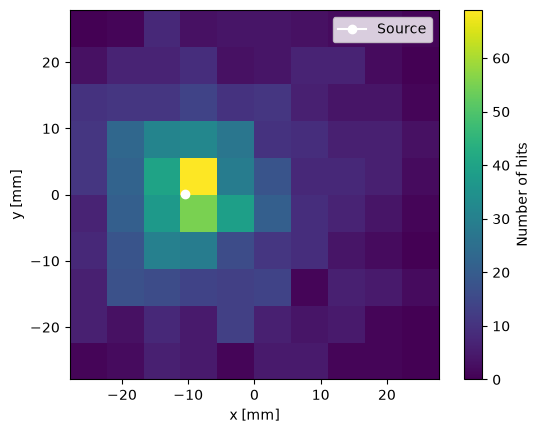

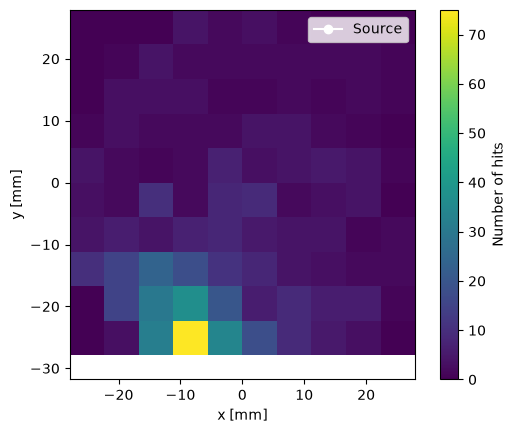

In [31]:
plot_event_hits('../out/xe_lt_s2/xe_lt_s2_0000.h5', 0, config=config)
plot_event_hits('../out/xe_lt_s2/xe_lt_s2_0000.h5', 573, config=config)

In [32]:
def n_evs_vs_R(path:str):
    """Function that plots the number of hits detected per event in every SIPM, as a function of the radius where the photons are produced

    Args:
        path (str): path to the h5 file to be plotted
    """
    data_sensors, _ = data_reading_wo_pd(path, 'sensor_hits')
    data_sources, _ = data_reading_wo_pd(path, 'sources')

    events = np.asarray(data_sources['event'])

    # R de cada fuente
    R = np.hypot(
        data_sources['x'],
        data_sources['y']
    )

    # Número de hits por evento, incluyendo los que tienen 0
    n_hits_all = np.bincount(
        data_sensors['event']
    )

    n_hits = n_hits_all[events]

    plt.plot(R, n_hits , '.')

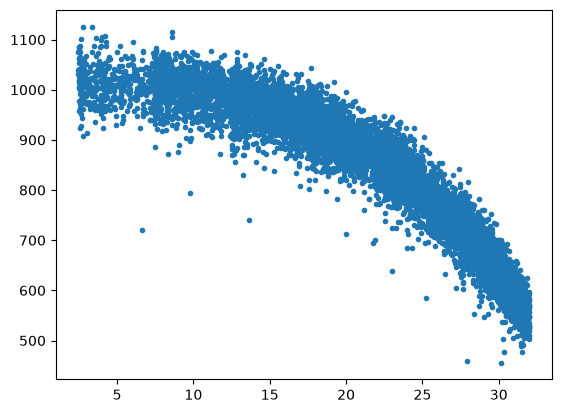

In [33]:
n_evs_vs_R('../out/xe_lt_s2/xe_lt_s2_0001.h5')

In [34]:
def wire_positions(config:np.ndarray) -> np.ndarray:
    """Genera las posiciones de los hilos antes de la rotación, siguiendo exactamente la lógica del código C++.

    Args:
        config (np.ndarray): Array containing the configuration parameters of the simulation

    Returns:
        np.ndarray: sorted y positions of the wires
    """
    drift_diam = 64  # Teño que metelo á man porque non o gardei no h5
    thin_wire_pitch = float(config[config['name'] == b'thin_wire_pitch']['value'][0])
    
    half_n_wires = int(np.floor(drift_diam / 2 / thin_wire_pitch))

    pos = []

    for i in range(half_n_wires):
        pos.append(-thin_wire_pitch * (i + 0.5))
        pos.append(+thin_wire_pitch * (i + 0.5))

    return np.sort(pos)

In [35]:
def find_wire(x_rot:float, y_rot:float, wire_positions:np.array, wire_rot:float) -> tuple[float, float]:
    """
    Identifica el wire a partir de un evento en coordenadas rotadas.

    Parameters
    ----------
    x_rot, y_rot : float
        Coordenadas rotadas del evento.

    wire_positions : array-like
        Posiciones Y de los wires en el sistema original.

    wire_rot : float
        Ángulo de rotación de los wires, en radianes.

    Returns
    -------
    x_wire : float
        Posición del evento a lo largo del wire.

    y_wire : float
        Posición Y del wire.

    """

    # wire_positions = wire_positions(config)
    # thin_wire_rot = float(config[config['name'] == b'thin_wire_rot']['value'][0])

    x_rot = np.asarray(x_rot)
    y_rot = np.asarray(y_rot)
    wire_positions = np.asarray(wire_positions)

    
    c = np.cos(np.deg2rad(wire_rot))
    s = np.sin(np.deg2rad(wire_rot))

    # Desrotar evento
    x = c * x_rot + s * y_rot
    y = -s * x_rot + c * y_rot

    # Encontrar wire
    
    wire_index = np.argmin(
    np.abs(y[:, None] - wire_positions[None, :]),
    axis=1
)

# wire_y = wire_positions[wire_index]
    wire_y = wire_positions[wire_index]

    #Rotar de nuevo para encontrar las coordenadas del hilo en el sistema simulado
    x_wire = c * x - s * wire_y
    y_wire = s * x + c * wire_y

    return x_wire, y_wire


In [36]:
# thin_wire_pitch = float(config[config['name'] == b'thin_wire_pitch']['value'][0])
# thin_wire_rot = float(config[config['name'] == b'thin_wire_rot']['value'][0])
# drift_diam = 64 # Teño que metelo á man porque non o gardei no h5
# wire_poss = wire_positions(config)

# drift_length = float(config[config['name'] == b'drift_length']['value'][0])
# frame_thick_mesh = float(config[config['name'] == b'frame_thick_mesh']['value'][0])
# d_gate_wire = float(config[config['name'] == b'd_gate_wire']['value'][0])
# z_wire = drift_length/2 + frame_thick_mesh + d_gate_wire



In [37]:
def gate_wire_relation(x_wire:float, y_wire:float, z_wire:float, x_source:float, y_source:float, z_source:float, pitch:float) -> tuple[float, float]:
    """Function that computes the correspondence between a point generated in the wire and where it came from in the gate. 
        The wire coordinates correspond to the true position of the wire, while the source coordinates correspond to the position 
        near the wire where the photon is generated

    Args:
        x_wire (float): _description_
        y_wire (float): _description_
        z_wire (float): _description_
        x_source (float): _description_
        y_source (float): _description_
        z_source (float): _description_
        pitch (float): Separation between wires

    Returns:
        tuple[float, float]: (x, y)postion from which the electron drifts from the gate to produce a photon in the source
    """     

    mask_x = (pitch / 2 / (np.pi / 2) * np.atan((x_source - x_wire ) / (z_wire - z_source)) < - pitch / 2) & (pitch / 2 / (np.pi / 2) * np.atan((x_source - x_wire ) / (z_wire - z_source)) > pitch / 2)
    mask_y = (pitch / 2 / (np.pi / 2) * np.atan((y_source - y_wire ) / (z_wire - z_source)) < - pitch / 2) & (pitch / 2 / (np.pi / 2) * np.atan((y_source - y_wire ) / (z_wire - z_source)) > pitch / 2)
    if np.any(mask_x):
        print('Value in x out of range')
    if np.any(mask_y):
            print('Value in y out of range')
    x_gate = x_wire + pitch / 2 / (np.pi / 2) * np.atan((x_source - x_wire ) / (z_wire - z_source))
    y_gate = y_wire + pitch / 2 / (np.pi / 2) * np.atan((y_source - y_wire) / (z_wire - z_source))
    return x_gate, y_gate

def obtain_gate_source(x_source, y_source, z_source, pitch, z_wire, wire_poss, thin_wire_rot):
    x_source = np.asarray(x_source)
    y_source = np.asarray(y_source)
    z_source = np.asarray(z_source)
    x_wire, y_wire = find_wire(x_source, y_source, wire_poss,thin_wire_rot)

    x_gate, y_gate = gate_wire_relation(x_wire, y_wire, z_wire, x_source, y_source, z_source, pitch)

    return x_gate, y_gate 
    

    


In [38]:
def plot_sources_and_wires(path:str, config:np.ndarray, n_events:int=None, seed:int=None) -> tuple[plt.Figure, plt.Axes.axes]:
    """Function that plots the sources of photons together with the wire where they have been generated, as well as the correspondent coordinates of the gate where the 
        electron comes from


    Args:
        path (str): path to the file to be plotted
        config (np.ndarray): array containing the configuration parameters of the simulation
        n_events (int, optional): number of events to be plotted. Defaults to None.
        seed (int, optional): seed of random generators for reproducibility. Defaults to None.

    Raises:
        ValueError: If more events than exist on the file are requested

    Returns:
        tuple[plt.Figure, plt.Axes.axes]: figure and ax of the plot
    """
    # Read sources
    sources = data_reading(path, "sources")

    # Select random events
    if n_events is not None:

        available_events = sources["event"].unique()

        if n_events > len(available_events):
            raise ValueError(
                f"Requested {n_events} events, "
                f"but only {len(available_events)} are available."
            )

        rng = np.random.default_rng(seed)

        selected_events = rng.choice(
            available_events,
            size=n_events,
            replace=False
        )

        sources = sources[
            sources["event"].isin(selected_events)
        ]

    # Plot
    fig, ax = plt.subplots()


    x_sources = sources['x']
    y_sources = sources['y']
    z_sources = sources['z']
    ax.scatter(
        x_sources,
        y_sources,
        s=3
    )

    thin_wire_pitch = float(config[config['name'] == b'thin_wire_pitch']['value'][0])
    thin_wire_rot = float(config[config['name'] == b'thin_wire_rot']['value'][0])

    drift_length = float(config[config['name'] == b'drift_length']['value'][0])
    frame_thick_mesh = float(config[config['name'] == b'frame_thick_mesh']['value'][0])
    d_gate_wire = float(config[config['name'] == b'd_gate_wire']['value'][0])
    z_wire = drift_length/2 + frame_thick_mesh + d_gate_wire

    xs_gate, ys_gate = obtain_gate_source(x_sources, y_sources, z_sources, thin_wire_pitch, z_wire, wire_positions(config), thin_wire_rot)
    ax.scatter(xs_gate , ys_gate , s=10, color='r')

    xs_wire, ys_wire = find_wire(x_sources, y_sources, wire_positions(config), thin_wire_rot)
    ax.scatter(xs_wire, ys_wire, s=3, color='green')

    ax.set_xlabel("X [mm]")
    ax.set_ylabel("Y [mm]")
    ax.set_title("Source positions")

    ax.set_aspect("equal")

    return fig, ax

/tmp/ipykernel_2450/1466344580.py:19: RuntimeWarning: divide by zero encountered in divide
  mask_x = (pitch / 2 / (np.pi / 2) * np.atan((x_source - x_wire ) / (z_wire - z_source)) < - pitch / 2) & (pitch / 2 / (np.pi / 2) * np.atan((x_source - x_wire ) / (z_wire - z_source)) > pitch / 2)
/tmp/ipykernel_2450/1466344580.py:20: RuntimeWarning: divide by zero encountered in divide
  mask_y = (pitch / 2 / (np.pi / 2) * np.atan((y_source - y_wire ) / (z_wire - z_source)) < - pitch / 2) & (pitch / 2 / (np.pi / 2) * np.atan((y_source - y_wire ) / (z_wire - z_source)) > pitch / 2)
/tmp/ipykernel_2450/1466344580.py:25: RuntimeWarning: divide by zero encountered in divide
  x_gate = x_wire + pitch / 2 / (np.pi / 2) * np.atan((x_source - x_wire ) / (z_wire - z_source))
/tmp/ipykernel_2450/1466344580.py:26: RuntimeWarning: divide by zero encountered in divide
  y_gate = y_wire + pitch / 2 / (np.pi / 2) * np.atan((y_source - y_wire) / (z_wire - z_source))


(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Source positions'}, xlabel='X [mm]', ylabel='Y [mm]'>)

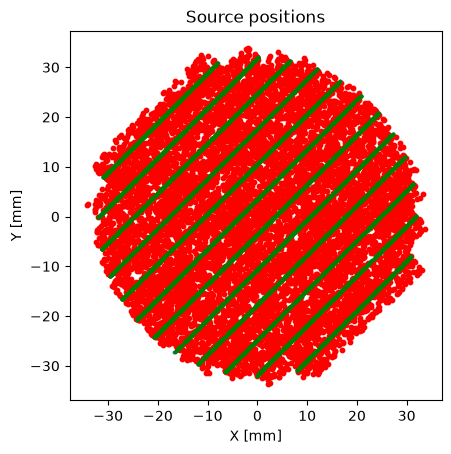

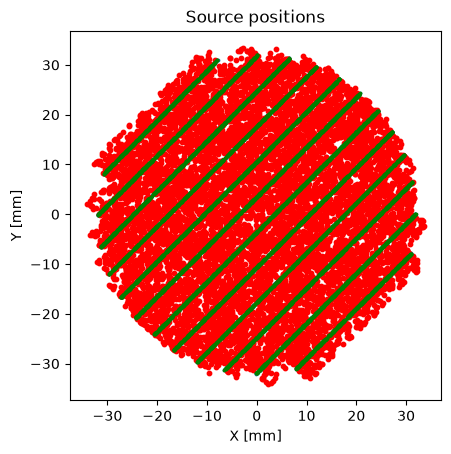

In [39]:
plot_sources_and_wires('../out/xe_lt_s2/xe_lt_s2_0000.h5', config=config, n_events=10000)
plot_sources_and_wires('../out/xe_lt_s2/xe_lt_s2_0001.h5', config=config, n_events=10000)

In [42]:
def light_collection_efficiency(dir_path, sensor_id, config, n_particles=10000, n_events=None):
    sources = full_data_reading_wo_pd(dir_path, 'sources')
    hits = full_data_reading_wo_pd(dir_path, 'sensor_hits')

    if n_events != None:
        sources = sources[:n_events]
        hits = hits[:n_events]

    sensor_filter_mask = hits['sensor_id'] == sensor_id 
    sensor_filtered_events = hits[sensor_filter_mask]['event']

    source_mask = np.isin(sources['event'], sensor_filtered_events, )
    sensor_filtered_sources = sources[source_mask]

    sensor_filtered_x_sources = sensor_filtered_sources['x']
    sensor_filtered_y_sources = sensor_filtered_sources['y']
    sensor_filtered_z_sources = sensor_filtered_sources['z']


    drift_length = float(config[config['name'] == b'drift_length']['value'][0])
    frame_thick_mesh = float(config[config['name'] == b'frame_thick_mesh']['value'][0])
    d_gate_wire = float(config[config['name'] == b'd_gate_wire']['value'][0])
    z_wire = drift_length/2 + frame_thick_mesh + d_gate_wire
    thin_wire_rot = float(config[config['name'] == b'thin_wire_rot']['value'][0])
    thin_wire_pitch = float(config[config['name'] == b'thin_wire_pitch']['value'][0])

    xs_gate, ys_gate = obtain_gate_source(sensor_filtered_x_sources,sensor_filtered_y_sources, sensor_filtered_z_sources, thin_wire_pitch, z_wire, wire_positions(config), thin_wire_rot)
    # plt.hist2d(xs_gate, ys_gate, bins=100)


    events_with_hits, n_hits_per_event_with_hits = np.unique(sensor_filtered_events, return_counts=True )

    n_hits = np.zeros(len(sensor_filtered_sources), dtype=int)
    idx = np.searchsorted(events_with_hits, sensor_filtered_sources['event'])

    valid = (
        idx < len(events_with_hits)
    ) & (
        events_with_hits[
            np.clip(idx, 0, len(events_with_hits) - 1)
        ] == sensor_filtered_sources['event']
    )

    n_hits[valid] = n_hits_per_event_with_hits[idx[valid]]

    sources_h, xedges, yedges = np.histogram2d(xs_gate, ys_gate, bins = 100)
    
    weighted_h, _, _ = np.histogram2d(xs_gate, ys_gate, bins = 100, weights=n_hits)

    coll_eff = weighted_h  / sources_h / n_particles * 100 #to give it in percentage

    coll_eff[np.isnan(coll_eff)] = 0

    
    print(sum(sum(coll_eff)) / (100 * 100))

    fig, ax = plt.subplots()
    #We need to do the transpose and start lower because of the way imshow works
    im = ax.imshow(coll_eff.T, origin='lower', extent=[xedges[0], xedges[-1], yedges[0],yedges[-1]])

    plt.colorbar(im, ax=ax, label='Collection efficiency (%)')
    sipm_pos = sipm_position(sensor_id, config=config)
    fig.suptitle(f'Light collection efficiency for sensor nr. {sensor_id} \n(position: ({sipm_pos[0]: .1f}, {sipm_pos[1]: .1f}))')
    
    return float(sum(sum(coll_eff)) / (100 * 100))

0.008645799870280446


/tmp/ipykernel_2450/1466344580.py:19: RuntimeWarning: divide by zero encountered in divide
  mask_x = (pitch / 2 / (np.pi / 2) * np.atan((x_source - x_wire ) / (z_wire - z_source)) < - pitch / 2) & (pitch / 2 / (np.pi / 2) * np.atan((x_source - x_wire ) / (z_wire - z_source)) > pitch / 2)
/tmp/ipykernel_2450/1466344580.py:20: RuntimeWarning: divide by zero encountered in divide
  mask_y = (pitch / 2 / (np.pi / 2) * np.atan((y_source - y_wire ) / (z_wire - z_source)) < - pitch / 2) & (pitch / 2 / (np.pi / 2) * np.atan((y_source - y_wire ) / (z_wire - z_source)) > pitch / 2)
/tmp/ipykernel_2450/1466344580.py:25: RuntimeWarning: divide by zero encountered in divide
  x_gate = x_wire + pitch / 2 / (np.pi / 2) * np.atan((x_source - x_wire ) / (z_wire - z_source))
/tmp/ipykernel_2450/1466344580.py:26: RuntimeWarning: divide by zero encountered in divide
  y_gate = y_wire + pitch / 2 / (np.pi / 2) * np.atan((y_source - y_wire) / (z_wire - z_source))
/tmp/ipykernel_2450/3131907188.py:50: Runti

0.008645799870280446

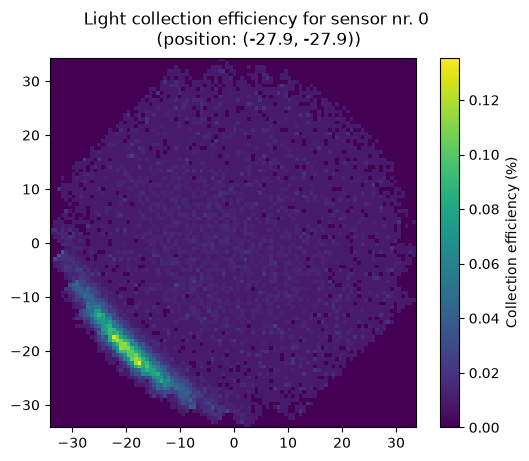

In [43]:
light_collection_efficiency(lt2_directory, 0, config=config)

In [44]:
# mean_LCE = 0
# for i in range(100):
#     mean_LCE += light_collection_efficiency(lt2_directory, i)
# print(mean_LCE)

In [47]:
def total_light_collection_efficiency(dir_path, n_particles=10000, n_events=None):
    sources = full_data_reading_wo_pd(dir_path, 'sources')
    hits = full_data_reading_wo_pd(dir_path, 'sensor_hits')

    if n_events != None:
        sources = sources[:n_events]
        hits = hits[:n_events]

    drift_length = float(config[config['name'] == b'drift_length']['value'][0])
    frame_thick_mesh = float(config[config['name'] == b'frame_thick_mesh']['value'][0])
    d_gate_wire = float(config[config['name'] == b'd_gate_wire']['value'][0])
    z_wire = drift_length/2 + frame_thick_mesh + d_gate_wire
    thin_wire_rot = float(config[config['name'] == b'thin_wire_rot']['value'][0])
    thin_wire_pitch = float(config[config['name'] == b'thin_wire_pitch']['value'][0])

    xs_gate, ys_gate = obtain_gate_source(sources['x'], sources['y'], sources['z'], thin_wire_pitch, z_wire, wire_positions(config), thin_wire_rot)
    # print(xs_gate)
    events_with_hits, n_hits_per_event_with_hits = np.unique(hits['event'], return_counts=True )

    n_hits = np.zeros(len(sources), dtype=int)
    idx = np.searchsorted(events_with_hits, sources['event'])

    valid = (
        idx < len(events_with_hits)
    ) & (
        events_with_hits[
            np.clip(idx, 0, len(events_with_hits) - 1)
        ] == sources['event']
    )

    n_hits[valid] = n_hits_per_event_with_hits[idx[valid]]

    sources_h, xedges, yedges = np.histogram2d(xs_gate, ys_gate, bins = 100)

    weighted_h, _, _ = np.histogram2d(xs_gate, ys_gate, bins = 100, weights=n_hits)

    coll_eff = weighted_h  / sources_h / n_particles * 100 #to give it in percentage

    coll_eff[np.isnan(coll_eff)] = 0

    
    print(sum(sum(coll_eff)) / (100 * 100))
    

    fig, ax = plt.subplots()
    #We need to do the transpose and start lower because of the way imshow works
    im = ax.imshow(coll_eff.T, origin='lower', extent=[xedges[0], xedges[-1], yedges[0],yedges[-1]])

    plt.colorbar(im, ax=ax, label='Collection efficiency (%)')
    
    fig.suptitle(f'Total Light collection efficiency')
    return coll_eff

/tmp/ipykernel_2450/1466344580.py:19: RuntimeWarning: divide by zero encountered in divide
  mask_x = (pitch / 2 / (np.pi / 2) * np.atan((x_source - x_wire ) / (z_wire - z_source)) < - pitch / 2) & (pitch / 2 / (np.pi / 2) * np.atan((x_source - x_wire ) / (z_wire - z_source)) > pitch / 2)
/tmp/ipykernel_2450/1466344580.py:20: RuntimeWarning: divide by zero encountered in divide
  mask_y = (pitch / 2 / (np.pi / 2) * np.atan((y_source - y_wire ) / (z_wire - z_source)) < - pitch / 2) & (pitch / 2 / (np.pi / 2) * np.atan((y_source - y_wire ) / (z_wire - z_source)) > pitch / 2)
/tmp/ipykernel_2450/1466344580.py:25: RuntimeWarning: divide by zero encountered in divide
  x_gate = x_wire + pitch / 2 / (np.pi / 2) * np.atan((x_source - x_wire ) / (z_wire - z_source))
/tmp/ipykernel_2450/1466344580.py:26: RuntimeWarning: divide by zero encountered in divide
  y_gate = y_wire + pitch / 2 / (np.pi / 2) * np.atan((y_source - y_wire) / (z_wire - z_source))


5.8697759517056225


/tmp/ipykernel_2450/528957520.py:37: RuntimeWarning: invalid value encountered in divide
  coll_eff = weighted_h  / sources_h / n_particles * 100 #to give it in percentage


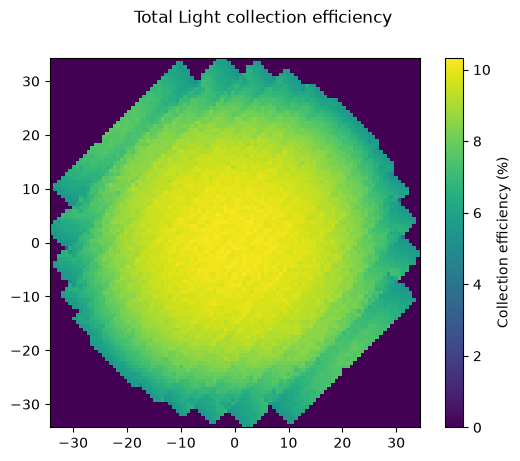

In [48]:
h=total_light_collection_efficiency(lt2_directory)

In [49]:
c = np.isinf(h)

In [50]:
sources = full_data_reading_wo_pd(lt2_directory, 'sources')
hits = full_data_reading_wo_pd(lt2_directory, 'sensor_hits')

np.unique(hits['event'], return_counts=True)


(array([     0,      1,      2, ..., 119997, 119998, 119999],
       shape=(119972,), dtype=uint64),
 array([1030,  884,  696, ...,  857,  788,  721], shape=(119972,)))

In [51]:
a = np.array([[3,3,3], [2, 2, 2], [1, 1, 1]])
b = np.array([[3,2,1], [3, 2, 1], [3, 2, 0]])

In [52]:
a / b


/tmp/ipykernel_2450/221305628.py:1: RuntimeWarning: divide by zero encountered in divide
  a / b


array([[1.        , 1.5       , 3.        ],
       [0.66666667, 1.        , 2.        ],
       [0.33333333, 0.5       ,        inf]])